# Model cases

Runs the cases for the report on the base model (`model/microgrid.py`) plus add-ons (`model/extensions.py`).
Each case: build the base model → apply add-ons → solve → validate → add a row to the results table.
Every case starts from a fresh `Params()`, so changes never carry over between runs. Equations: `docs/formulation.md`.
Tables (CSV) and figures (PNG) are saved to `analysis/results/`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "model"))
from params import Params, Y, V, A_Y
from microgrid import build, validate, load_inputs, emissions
from extensions import (add_outage, peak_day, force_battery, min_imports, min_peak, allow_unmet,
                        no_investment, relax_binaries)

OUT = ROOT / "analysis" / "results"
OUT.mkdir(exist_ok=True)
N = {y: len(A_Y[y]) for y in Y}          # n_y: undiscounted weights for physical totals
STATUS = {2: "OPTIMAL", 3: "INFEASIBLE", 4: "INF_OR_UNBD", 9: "TIME_LIMIT"}
TOL = 1e-3                               # kWh, "positive" threshold for flows

In [2]:
def run(case, p=None, alpha=None, battery_test=False, objective=None, Z_star=None, unmet_all=False,
        baseline=False, relax=False):
    """Solve one case. Returns (row of results, detail) where detail has unmet kWh per year and
    2049 hourly battery results. alpha: outage on the peak day; battery_test: non-zero battery test;
    objective: "imports" or "peak" (needs Z_star); unmet_all: infeasibility recovery (u allowed in every hour);
    baseline: no new investment; relax: LP relaxation of the binary build decisions."""
    p = p or Params()
    m, inv, ops, cost = build(p)
    m.Params.OutputFlag = 0
    if alpha is not None:
        add_outage(m, ops, cost, p, alpha, peak_day(load_inputs(p)))
    if unmet_all:
        allow_unmet(m, ops, cost, p)
    if battery_test:
        force_battery(m, inv, p)
    if baseline:
        no_investment(m, inv)
    if relax:
        relax_binaries(m, inv)
    if objective == "imports":
        min_imports(m, ops, p, Z_star)
    if objective == "peak":
        min_peak(m, ops, p, Z_star)
    m.optimize()
    if m.Status == 4:                    # separate infeasible from unbounded
        m.Params.DualReductions = 0
        m.optimize()
    row = {"case": case, "status": STATUS.get(m.Status, m.Status), "Solve time (s)": m.Runtime,
           "Variables": m.NumVars, "Constraints": m.NumConstrs, "Binary variables": m.NumBinVars}
    if m.SolCount == 0:
        print(f"{case}: no solution, status {row['status']}")
        return row, None
    print(case); validate(p, ops)

    s = m._scale
    X = {y: {k: o[k].X for k in ("imp", "exp", "pv", "ch", "dis", "soc", "u")} for y, o in ops.items()}
    total = lambda k: sum(N[y] * s * X[y][k].sum() for y in Y)          # 25-year physical total, kWh
    vals = {k: float(e.getValue()) for k, e in cost.items()}
    Z = vals["C_inv"] + vals["C_OM"] + vals["C_rep"] - vals["C_RV"] + vals["C_grid"]   # physical lifecycle cost

    row["Z ($M)"] = Z / 1e6
    row.update({f"{k} ($M)": v / 1e6 for k, v in vals.items()})
    for v in V:
        row[f"PV {v} (kW)"] = inv["xPV"][v].X
        row[f"Battery {v} (kWh)"] = inv["xB"][v].X
        row[f"zPV {v}"] = round(inv["zPV"][v].X, 3)     # fractional only in the LP relaxation
        row[f"zB {v}"] = round(inv["zB"][v].X, 3)
    row["PV total (kW)"] = sum(inv["xPV"][v].X for v in V)
    row["Battery total (kWh)"] = sum(inv["xB"][v].X for v in V)
    row["Imports (GWh)"] = total("imp") / 1e6
    row["Exports (GWh)"] = total("exp") / 1e6
    row["Peak draw (MW)"] = max(X[y]["imp"].max() for y in Y) / 1e3
    row["Emissions (t CO2e)"] = emissions(p, ops, s) / 1e3
    row["Charge (MWh)"] = total("ch") / 1e3
    row["Discharge (MWh)"] = total("dis") / 1e3
    row["Unmet (MWh)"] = total("u") / 1e3
    row["Unmet hours (rep. years)"] = int(sum((X[y]["u"] > TOL).sum() for y in Y))
    row["Max hourly unmet (MW)"] = max(X[y]["u"].max() for y in Y) / 1e3

    # Validation beyond validate(): Gurobi's max violations cover every constraint (1)-(15), bounds and binaries
    row["Max violation"] = max(m.ConstrVio, m.BoundVio, m.IntVio if m.IsMIP else 0.0)
    if objective is None:                # objective = sum of cost components (+ penalty)
        row["Obj - components ($)"] = m.ObjVal - (Z + vals.get("C_unmet", 0.0))
    row["Hours import & export"] = int(sum(((X[y]["imp"] > TOL) & (X[y]["exp"] > TOL)).sum() for y in Y))
    row["Hours charge & discharge"] = int(sum(((X[y]["ch"] > TOL) & (X[y]["dis"] > TOL)).sum() for y in Y))
    row["Export credit capped (min c_imp < c_exp)"] = min(p.tou.values()) < p.c_exp
    try:
        row["MIP gap"] = m.MIPGap
    except AttributeError:               # not defined for an LP or a multi-objective solve
        row["MIP gap"] = np.nan

    # Binding limits: which caps the solution sits on (explains why results change between runs)
    bind = []
    if row["PV total (kW)"] >= p.PV_max - TOL:
        bind.append("PV at PV_max (3)")
    if row["Battery total (kWh)"] >= p.B_max - TOL:
        bind.append("battery at B_max (4)")
    for k, cap, label in (("imp", p.G_imp_max, "imports at grid limit (12)"), ("exp", p.G_exp_max, "exports at limit (13)")):
        n = int(sum((X[y][k] >= cap * p.dt - TOL).sum() for y in Y)) if cap > 0 else 0
        if n:
            bind.append(f"{label}: {n} h")
    for name in ("cost_cap", "battery_test"):    # add-on constraints, if present
        c = m.getConstrByName(name)
        if c is not None and abs(c.Slack) <= 1e-6 * max(1.0, abs(c.RHS)):
            bind.append(name)
    row["Binding limits"] = "; ".join(bind) or "none"
    detail = {"unmet": {y: X[y]["u"].sum() for y in Y},
              "week": pd.DataFrame({k: X[2049][k] for k in ("soc", "ch", "dis")})}
    return row, detail


def solve_or_recover(case, p):
    """Run a stress case; if infeasible, report it and re-run with unmet demand allowed in every hour."""
    row, details[case] = run(case, p)
    rows = [row]
    if details[case] is None and row["status"] in ("INFEASIBLE", "INF_OR_UNBD"):
        name = case + " [recovery, u allowed]"
        rec, details[name] = run(name, p, unmet_all=True)
        rows.append(rec)
    return rows

## Base case, non-zero battery test and alternative objectives
- Base: minimize lifecycle cost Z; its optimum is Z*.
- Non-zero battery test: base objective with Σ x^B ≥ B^Test = 4,000 kWh.
- Alternative objectives: minimize 25-year grid imports, or the peak grid draw, with Z ≤ (1 + ε) Z*, ε = 0.10.
  Solved lexicographically: the alternative objective first, then Z among its optimal solutions (tie-break), so the
  reported cost and design are the cheapest of the equally good alternatives.

In [3]:
base, base_d = run("Base (min cost)")
Z_star = base["Z ($M)"] * 1e6
bt, bt_d = run("Non-zero battery test", battery_test=True)
rows = [base, bt,
        run("Min grid imports (Z ≤ 1.1 Z*)", objective="imports", Z_star=Z_star)[0],
        run("Min peak draw (Z ≤ 1.1 Z*)", objective="peak", Z_star=Z_star)[0]]
objectives = pd.DataFrame(rows).set_index("case")
objectives.round(2).T

Set parameter Username


Set parameter LicenseID to value 2889055


Academic license - for non-commercial use only - expires 2027-11-26


Base (min cost)
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Non-zero battery test
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 400-4,000 of 4,000 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 400-4,000 of 4,000 kWh | unmet 0 kWh


Min grid imports (Z ≤ 1.1 Z*)
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 5.5e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 6.4e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 1.8e-10 kWh | daily shift sum 1.5e-10 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 2.4e-10 kWh | daily shift sum 2.4e-10 | SOC 0-0 of 0 kWh | unmet 0 kWh


Min peak draw (Z ≤ 1.1 Z*)
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 5.5e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 2.9e-10 kWh | daily shift sum 2.9e-10 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 5.9e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 3.0e-10 kWh | daily shift sum 3.0e-10 | SOC 1,682-16,816 of 16,816 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 4.5e-12 | SOC 1,682-16,816 of 16,816 kWh | unmet 0 kWh


case,Base (min cost),Non-zero battery test,Min grid imports (Z ≤ 1.1 Z*),Min peak draw (Z ≤ 1.1 Z*)
status,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL
Solve time (s),13.85,16.28,17.02,14.79
Variables,350418,350418,350418,350419
Constraints,308450,308451,308451,352251
Binary variables,4,4,4,4
Z ($M),207.37,207.93,207.37,211.82
C_inv ($M),13.73,14.45,13.73,7.99
C_OM ($M),2.34,2.62,2.34,2.02
C_rep ($M),0.0,0.0,0.0,0.0
C_RV ($M),0.16,0.23,0.16,1.7


## Baseline comparison
Existing system with no new investment (x = z = 0; the existing 70 kW of PV stays), all grid. Two versions:
- **No investment, no shifting (φ = 0):** UW as it is today. The official baseline.
- **No investment, with shifting (φ = 0.10):** separates the value of load shifting from the value of PV/battery.

Equivalent annual saving = lifecycle saving / Σ_{a=2028}^{2052} D_a (the constant yearly amount with the same present value).

In [4]:
bl0, _ = run("Baseline: no investment, no shifting", Params(phi=0.0), baseline=True)
bl1, _ = run("Baseline: no investment, with shifting", baseline=True)
baseline_tbl = pd.DataFrame([bl0, bl1, base]).set_index("case")
AF = sum(Params().D(a) for a in range(2028, 2053))
parts = {"Total (investment + shifting)": (bl0, base), "From load shifting": (bl0, bl1),
         "From PV/battery investment": (bl1, base)}
savings = pd.DataFrame({name: {
    "Lifecycle saving ($M)": a["Z ($M)"] - b["Z ($M)"],
    "Equivalent annual saving ($M/yr)": (a["Z ($M)"] - b["Z ($M)"]) / AF,
    "Imports avoided (GWh)": a["Imports (GWh)"] - b["Imports (GWh)"],
    "Emissions avoided (t CO2e)": a["Emissions (t CO2e)"] - b["Emissions (t CO2e)"],
    "Peak reduction (MW)": a["Peak draw (MW)"] - b["Peak draw (MW)"]} for name, (a, b) in parts.items()}).T
baseline_tbl.to_csv(OUT / "baseline.csv"); savings.to_csv(OUT / "baseline_savings.csv")
display(baseline_tbl[["Z ($M)", "C_inv ($M)", "C_OM ($M)", "C_grid ($M)", "PV total (kW)", "Imports (GWh)",
                      "Peak draw (MW)", "Emissions (t CO2e)"]].round(2))
savings.round(2)

Baseline: no investment, no shifting
  2028: OK | balance error 0.0e+00 kWh | daily shift sum 0.0e+00 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 1.8e-12 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 0.0e+00 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 0.0e+00 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 0.0e+00 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh


Baseline: no investment, with shifting
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 3.6e-12 kWh | daily shift sum 6.4e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 3.6e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


,Z ($M),C_inv ($M),C_OM ($M),C_grid ($M),PV total (kW),Imports (GWh),Peak draw (MW),Emissions (t CO2e)
case,,,,,,,,
"Baseline: no investment, no shifting",216.96,0.00,0.00,216.96,0.0,3197.24,26.07,188637.15
"Baseline: no investment, with shifting",212.28,0.00,0.00,212.28,0.0,3197.24,26.07,188637.15
Base (min cost),207.37,13.73,2.34,191.46,6860.0,2947.29,26.07,173890.09


,Lifecycle saving ($M),Equivalent annual saving ($M/yr),Imports avoided (GWh),Emissions avoided (t CO2e),Peak reduction (MW)
Total (investment + shifting),9.59,0.65,249.95,14747.06,0.0
From load shifting,4.68,0.32,0.00,0.00,0.0
From PV/battery investment,4.91,0.33,249.95,14747.06,0.0


## Comparison of approaches
Solution quality (cost, design) and computational effort (model size, solve time):
- **MILP (base):** binary build decisions z ∈ {0, 1}, the formulation in the report.
- **LP relaxation:** z ∈ [0, 1]. Fixed costs F and minimum sizes then only apply in proportion to z, so the LP is a lower
  bound on Z; the comparison shows whether the binaries change the answer and what they cost in solve time.
- **MILP without demand flexibility (φ = 0):** the base formulation without our extension (14)-(15) active, showing what
  the flexibility formulation adds to solution quality and to computational effort.

In [5]:
lp, _ = run("LP relaxation (z continuous)", relax=True)
noflex, _ = run("MILP without flexibility (φ = 0)", Params(phi=0.0))
approaches = pd.DataFrame([base, lp, noflex]).set_index("case")
approaches["Z vs MILP (%)"] = 100 * (approaches["Z ($M)"] / base["Z ($M)"] - 1)
approaches = approaches[["Z ($M)", "Z vs MILP (%)", "PV 2028 (kW)", "PV 2040 (kW)", "Battery 2028 (kWh)",
                         "Battery 2040 (kWh)", "zPV 2028", "zPV 2040", "zB 2028", "zB 2040", "Peak draw (MW)",
                         "Imports (GWh)", "Emissions (t CO2e)", "Variables", "Constraints", "Binary variables",
                         "Solve time (s)", "MIP gap"]]
approaches.to_csv(OUT / "approaches.csv")
approaches.round(3).T

LP relaxation (z continuous)
  2028: OK | balance error 1.8e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 4.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 3.6e-12 kWh | daily shift sum 4.3e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 3.6e-12 kWh | daily shift sum 4.3e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


MILP without flexibility (φ = 0)
  2028: OK | balance error 0.0e+00 kWh | daily shift sum 0.0e+00 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 1.8e-12 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 1.8e-12 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 3.6e-12 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 3.6e-12 kWh | daily shift sum 0.0e+00 | SOC 0-0 of 0 kWh | unmet 0 kWh


case,Base (min cost),LP relaxation (z continuous),MILP without flexibility (φ = 0)
Z ($M),207.366,207.366,212.045
Z vs MILP (%),0.000,0.000,2.256
PV 2028 (kW),6860.000,6860.000,6860.000
PV 2040 (kW),0.000,0.000,0.000
Battery 2028 (kWh),0.000,0.000,0.000
Battery 2040 (kWh),0.000,0.000,0.000
zPV 2028,1.000,1.000,1.000
zPV 2040,-0.000,0.000,0.000
zB 2028,0.000,0.000,-0.000
zB 2040,-0.000,0.000,-0.000


## Resilience analysis
Outage on the peak-demand day (July 2) of every representative year. PV and battery are re-optimized in each run.
M = 10 CAD/kWh. Emissions are E^CO2 from the grid imports of each run (not discounted).

In [6]:
cases = [("Normal (α = 1)", None), ("Partial restriction (α = 0.5)", 0.5), ("Complete outage (α = 0)", 0.0)]
rows, unmet = [], {}
for name, alpha in cases:
    row, d = run(name, alpha=alpha)
    rows.append(row); unmet[name] = d["unmet"]
resilience = pd.DataFrame(rows).set_index("case").fillna(0)   # normal run has no C_unmet term
resilience.round(2).T

Normal (α = 1)
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Partial restriction (α = 0.5)
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 18,981 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 10,828 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 66,951 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 7.3e-12 | SOC 0-0 of 0 kWh | unmet 103,231 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 169,091 kWh


Complete outage (α = 0)
  2028: OK | balance error 7.3e-12 kWh | daily shift sum 3.0e-11 | SOC -0-0 of -0 kWh | unmet 384,213 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 354,376 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 432,183 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 7.3e-12 | SOC 0-0 of 0 kWh | unmet 468,463 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 534,323 kWh


case,Normal (α = 1),Partial restriction (α = 0.5),Complete outage (α = 0)
status,OPTIMAL,OPTIMAL,OPTIMAL
Solve time (s),13.59,8.48,8.6
Variables,350418,350418,350418
Constraints,308450,308450,308450
Binary variables,4,4,4
Z ($M),207.37,207.27,206.6
C_inv ($M),13.73,13.73,13.73
C_OM ($M),2.34,2.34,2.34
C_rep ($M),0.0,0.0,0.0
C_RV ($M),0.16,0.16,0.16


In [7]:
# Unmet demand on the outage day, by representative year (MWh)
(pd.DataFrame(unmet) / 1e3).round(1)

,Normal (α = 1),Partial restriction (α = 0.5),Complete outage (α = 0)
2028,0.0,19.0,384.2
2031,0.0,10.8,354.4
2037,0.0,67.0,432.2
2043,0.0,103.2,468.5
2049,0.0,169.1,534.3


## Sensitivity analysis
One parameter at a time; everything else at base values.
- **Battery capital cost:** c^B_2028, c^B_2040 and c^rep_2043 × k (F^B and m^B unchanged; C^RV uses the scaled costs).
- **Grid import price:** all TOU prices × k (time-of-use structure kept); export credit stays 0.0641 CAD/kWh.
- **PV capital cost:** c^PV_2028 and c^PV_2040 × k (F^PV and m^PV unchanged; C^RV uses the scaled costs).

In [8]:
MULTS = [0.50, 0.75, 1.00, 1.25, 1.50]

def battery_cost(k, p=None):
    p = p or Params()
    p.c_B = {v: k * c for v, c in p.c_B.items()}
    p.c_rep = k * p.c_rep
    return p

def pv_cost(k, p=None):
    p = p or Params()
    p.c_PV = {v: k * c for v, c in p.c_PV.items()}
    return p

def import_price(k, p=None):
    p = p or Params()
    p.tou = {period: k * c for period, c in p.tou.items()}
    return p

details = {}
sens_B = []
for k in MULTS:
    row, details[f"Battery cost x{k}"] = run(f"Battery cost x{k}", battery_cost(k))
    sens_B.append({"multiplier": k, **row})
sens_B = pd.DataFrame(sens_B)
sens_B.set_index("case").round(2).T

Battery cost x0.5
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x0.75
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x1.0
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x1.25
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x1.5
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


case,Battery cost x0.5,Battery cost x0.75,Battery cost x1.0,Battery cost x1.25,Battery cost x1.5
multiplier,0.5,0.75,1.0,1.25,1.5
status,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL
Solve time (s),13.56,14.42,13.84,13.74,14.01
Variables,350418,350418,350418,350418,350418
Constraints,308450,308450,308450,308450,308450
Binary variables,4,4,4,4,4
Z ($M),207.37,207.37,207.37,207.37,207.37
C_inv ($M),13.73,13.73,13.73,13.73,13.73
C_OM ($M),2.34,2.34,2.34,2.34,2.34
C_rep ($M),0.0,0.0,0.0,0.0,0.0


### Break-even battery cost
If no battery is built at any tested multiplier, first lower the multiplier until a battery is built, then bisect
between the highest multiplier with a battery and the lowest without one (tolerance 0.01).

In [9]:
built = lambda r: r["Battery total (kWh)"] > TOL
extra = []
if not sens_B.apply(built, axis=1).any():
    lo, hi = None, 0.50                      # lo: battery built, hi: no battery
    for k in [0.25, 0.10, 0.0]:
        row, details[f"Battery cost x{k}"] = run(f"Battery cost x{k}", battery_cost(k))
        extra.append({"multiplier": k, **row})
        if built(row):
            lo = k
            break
        hi = k
    if lo is None:
        print("No battery is built even at multiplier 0: battery capital cost alone cannot make it attractive.")
    else:
        while hi - lo > 0.01:
            k = round((lo + hi) / 2, 4)
            row, details[f"Battery cost x{k}"] = run(f"Battery cost x{k}", battery_cost(k))
            extra.append({"multiplier": k, **row})
            lo, hi = (k, hi) if built(row) else (lo, k)
        print(f"Break-even battery cost multiplier: between {lo} and {hi} "
              f"(c^B_2028 ≈ {lo * Params().c_B[2028]:.0f}-{hi * Params().c_B[2028]:.0f} CAD/kWh)")
sens_B_all = pd.concat([sens_B, pd.DataFrame(extra)]).sort_values("multiplier")
sens_B_all[["multiplier", "status", "Z ($M)", "Battery 2028 (kWh)", "Battery 2040 (kWh)", "PV total (kW)"]].round(3)

Battery cost x0.25
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x0.1
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 1,700-17,000 of 17,000 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 1,700-17,000 of 17,000 kWh | unmet 0 kWh


Battery cost x0.175
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x0.1375
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x0.1188
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Battery cost x0.1094
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 1,700-17,000 of 17,000 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 1,700-17,000 of 17,000 kWh | unmet 0 kWh


Break-even battery cost multiplier: between 0.1094 and 0.1188 (c^B_2028 ≈ 45-49 CAD/kWh)


,multiplier,status,Z ($M),Battery 2028 (kWh),Battery 2040 (kWh),PV total (kW)
1,0.100,OPTIMAL,207.329,0.0,17000.0,6860.0
5,0.109,OPTIMAL,207.353,0.0,17000.0,6860.0
4,0.119,OPTIMAL,207.366,0.0,0.0,6860.0
3,0.138,OPTIMAL,207.366,0.0,0.0,6860.0
2,0.175,OPTIMAL,207.366,0.0,0.0,6860.0
0,0.250,OPTIMAL,207.366,0.0,0.0,6860.0
0,0.500,OPTIMAL,207.366,0.0,0.0,6860.0
1,0.750,OPTIMAL,207.366,0.0,0.0,6860.0
2,1.000,OPTIMAL,207.366,0.0,0.0,6860.0
3,1.250,OPTIMAL,207.366,0.0,0.0,6860.0


In [10]:
sens_G = []
for k in MULTS:
    p = import_price(k)
    if min(p.tou.values()) < p.c_exp:
        print(f"Note x{k}: off-peak import price {p.tou['off']:.4f} < export credit {p.c_exp} CAD/kWh; "
              "the export credit is capped at the import price in those hours (no resale profit)")
    row, details[f"Import price x{k}"] = run(f"Import price x{k}", p)
    sens_G.append({"multiplier": k, **row})
sens_G = pd.DataFrame(sens_G)
sens_G.set_index("case").round(2).T

Note x0.5: off-peak import price 0.0455 < export credit 0.0641 CAD/kWh; the export credit is capped at the import price in those hours (no resale profit)


Import price x0.5
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.4e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 7.3e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 8.2e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 3.6e-12 kWh | daily shift sum 1.0e-11 | SOC 0-0 of 0 kWh | unmet 0 kWh


Import price x0.75
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 1.1e-11 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Import price x1.0
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Import price x1.25
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


Import price x1.5
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


case,Import price x0.5,Import price x0.75,Import price x1.0,Import price x1.25,Import price x1.5
multiplier,0.5,0.75,1.0,1.25,1.5
status,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL
Solve time (s),14.29,13.84,13.68,13.47,13.48
Variables,350418,350418,350418,350418,350418
Constraints,308450,308450,308450,308450,308450
Binary variables,4,4,4,4,4
Z ($M),106.14,158.21,207.37,255.23,303.1
C_inv ($M),0.0,5.06,13.73,13.73,13.73
C_OM ($M),0.0,0.84,2.34,2.34,2.34
C_rep ($M),0.0,0.0,0.0,0.0,0.0


In [11]:
sens_PV = []
for k in MULTS:
    row, details[f"PV cost x{k}"] = run(f"PV cost x{k}", pv_cost(k))
    sens_PV.append({"multiplier": k, **row})
sens_PV = pd.DataFrame(sens_PV)
sens_PV.set_index("case").round(2).T

PV cost x0.5
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


PV cost x0.75
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


PV cost x1.0
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


PV cost x1.25
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


PV cost x1.5
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 1.1e-11 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


case,PV cost x0.5,PV cost x0.75,PV cost x1.0,PV cost x1.25,PV cost x1.5
multiplier,0.5,0.75,1.0,1.25,1.5
status,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL
Solve time (s),13.82,13.6,13.74,13.68,13.86
Variables,350418,350418,350418,350418,350418
Constraints,308450,308450,308450,308450,308450
Binary variables,4,4,4,4,4
Z ($M),200.59,203.98,207.37,210.37,211.28
C_inv ($M),6.88,10.31,13.73,6.33,7.59
C_OM ($M),2.34,2.34,2.34,0.84,0.84
C_rep ($M),0.0,0.0,0.0,0.0,0.0


## Stress cases
- **S1 low solar:** lowest-generation scenario (S1, 1,544 kWh/kW per year) in every representative year.
- **S2 high growth:** g = 4%/yr (demand, critical load, peak and flexibility limits recalculated by the model); grid limits unchanged.
- **S3 discount rate:** r = 3% and 7% (all D_a and W_y recalculated; n_y unchanged).
- **S4 no export credit:** c^exp = 0, exports still allowed.
- **S5 combined financial:** low solar + battery cost × 1.5 + import price × 0.75.
- **S6 combined supply:** low solar + g = 4% + import price × 1.5.

Infeasible runs are reported, then re-run with unmet demand allowed in every hour at M = 10 CAD/kWh (same penalty as resilience).

In [12]:
sol = pd.read_csv(ROOT / "data" / "processed" / "Solar PV data cleaned.csv")[["S1_frac", "S2_frac", "S3_frac"]].sum()
LOW = sol.idxmin()
print("Annual kWh/kW by scenario:", sol.round(1).to_dict(), "-> lowest:", LOW)

def low_solar(p=None):
    p = p or Params()
    p.solar = {y: LOW for y in Y}
    return p

stress_def = {
    "S1 Low solar": low_solar(),
    "S2 Growth 4%": Params(g=0.04),
    "S3 Discount 3%": Params(r=0.03),
    "S3 Discount 7%": Params(r=0.07),
    "S4 No export credit": Params(c_exp=0.0),
    "S5 Combined financial": import_price(0.75, battery_cost(1.50, low_solar())),
    "S6 Combined supply": import_price(1.50, low_solar(Params(g=0.04))),
}
stress = []
for name, p in stress_def.items():
    stress += solve_or_recover(name, p)
stress = pd.DataFrame(stress).set_index("case")
stress.round(2).T

Annual kWh/kW by scenario: {'S1_frac': 1543.7, 'S2_frac': 1554.4, 'S3_frac': 1757.5} -> lowest: S1_frac


S1 Low solar
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 5.9e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 7.3e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


S2 Growth 4%: no solution, status INFEASIBLE


S2 Growth 4% [recovery, u allowed]
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 7.3e-12 kWh | daily shift sum 5.5e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 6.4e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 1.1e-11 | SOC 1,700-17,000 of 17,000 kWh | unmet 0 kWh
  2049: OK | balance error 1.5e-11 kWh | daily shift sum 6.4e-12 | SOC 1,700-17,000 of 17,000 kWh | unmet 1,245,826 kWh


S3 Discount 3%
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


S3 Discount 7%
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.8e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


S4 No export credit
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 3.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 5.0e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 6.4e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.6e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh


S5 Combined financial
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 3.6e-12 kWh | daily shift sum 5.9e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 3.6e-12 kWh | daily shift sum 4.1e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 1.3e-11 kWh | daily shift sum 8.2e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 1.0e-11 | SOC 0-0 of 0 kWh | unmet 0 kWh


S6 Combined supply: no solution, status INFEASIBLE


S6 Combined supply [recovery, u allowed]
  2028: OK | balance error 3.6e-12 kWh | daily shift sum 3.9e-12 | SOC -0-0 of -0 kWh | unmet 0 kWh
  2031: OK | balance error 7.3e-12 kWh | daily shift sum 6.4e-12 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2037: OK | balance error 7.3e-12 kWh | daily shift sum 2.3e-10 | SOC 0-0 of 0 kWh | unmet 0 kWh
  2043: OK | balance error 7.3e-12 kWh | daily shift sum 1.1e-11 | SOC 1,700-17,000 of 17,000 kWh | unmet 0 kWh
  2049: OK | balance error 7.3e-12 kWh | daily shift sum 8.2e-12 | SOC 1,700-17,000 of 17,000 kWh | unmet 1,165,690 kWh


case,S1 Low solar,S2 Growth 4%,"S2 Growth 4% [recovery, u allowed]",S3 Discount 3%,S3 Discount 7%,S4 No export credit,S5 Combined financial,S6 Combined supply,"S6 Combined supply [recovery, u allowed]"
status,OPTIMAL,INFEASIBLE,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,INFEASIBLE,OPTIMAL
Solve time (s),14.25,0.19,9.89,13.61,13.69,13.71,14.24,0.2,9.81
Variables,350418,350418,350418,350418,350418,350418,350418,350418,350418
Constraints,308450,308450,308450,308450,308450,308450,308450,308450,308450
Binary variables,4,4,4,4,4,4,4,4,4
Z ($M),208.06,NaN,268.38,252.9,174.05,207.37,158.2,NaN,393.8
C_inv ($M),13.73,NaN,16.69,13.73,13.73,13.73,5.06,NaN,16.69
C_OM ($M),2.34,NaN,3.53,2.87,1.94,2.34,0.84,NaN,3.53
C_rep ($M),0.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,0.0
C_RV ($M),0.16,NaN,0.47,0.26,0.1,0.16,1.39,NaN,0.47


## Results tables
Physical quantities (imports, exports, emissions, battery throughput, unmet demand) use n_y; costs use W_y.
In recovery runs, Z is the physical lifecycle cost and C_unmet the penalty, reported separately.

In [13]:
allrows = pd.concat([objectives.iloc[:1], sens_B_all.set_index("case"), sens_G.set_index("case"),
                     sens_PV.set_index("case"), stress])
allrows = allrows[~allrows.index.duplicated()]
Z0 = base["Z ($M)"]
allrows["Z change vs base (%)"] = 100 * (allrows["Z ($M)"] / Z0 - 1)
cols = ["status", "Solve time (s)", "MIP gap", "Binding limits", "PV 2028 (kW)", "PV 2040 (kW)", "Battery 2028 (kWh)", "Battery 2040 (kWh)", "zPV 2028", "zPV 2040",
        "zB 2028", "zB 2040", "PV total (kW)", "Battery total (kWh)", "Z ($M)", "Z change vs base (%)", "C_inv ($M)",
        "C_OM ($M)", "C_rep ($M)", "C_RV ($M)", "C_grid ($M)", "C_unmet ($M)", "Imports (GWh)", "Exports (GWh)",
        "Peak draw (MW)", "Emissions (t CO2e)", "Charge (MWh)", "Discharge (MWh)", "Unmet (MWh)",
        "Unmet hours (rep. years)", "Max hourly unmet (MW)", "Max violation", "Obj - components ($)",
        "Hours import & export", "Hours charge & discharge", "Export credit capped (min c_imp < c_exp)"]
allrows = allrows.reindex(columns=cols)
allrows.to_csv(OUT / "all_scenarios.csv")
for name, df in [("sensitivity_battery_cost", sens_B_all), ("sensitivity_import_price", sens_G),
                 ("sensitivity_pv_cost", sens_PV)]:
    df.set_index("case").reindex(columns=["multiplier"] + cols).to_csv(OUT / f"{name}.csv")
allrows.loc[stress.index].to_csv(OUT / "stress_cases.csv")
allrows.round(2).T

case,Base (min cost),Battery cost x0.1,Battery cost x0.1094,Battery cost x0.1188,Battery cost x0.1375,Battery cost x0.175,Battery cost x0.25,Battery cost x0.5,Battery cost x0.75,Battery cost x1.0,...,PV cost x1.5,S1 Low solar,S2 Growth 4%,"S2 Growth 4% [recovery, u allowed]",S3 Discount 3%,S3 Discount 7%,S4 No export credit,S5 Combined financial,S6 Combined supply,"S6 Combined supply [recovery, u allowed]"
status,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,...,OPTIMAL,OPTIMAL,INFEASIBLE,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,OPTIMAL,INFEASIBLE,OPTIMAL
Solve time (s),13.85,12.98,13.38,13.12,13.19,13.46,13.44,13.56,14.42,13.84,...,13.86,14.25,0.19,9.89,13.61,13.69,13.71,14.24,0.2,9.81
MIP gap,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,0.0
Binding limits,PV at PV_max (3),PV at PV_max (3); battery at B_max (4),PV at PV_max (3); battery at B_max (4),PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),...,PV at PV_max (3),PV at PV_max (3),NaN,PV at PV_max (3); battery at B_max (4); import...,PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),PV at PV_max (3),NaN,PV at PV_max (3); battery at B_max (4); import...
PV 2028 (kW),6860.0,6860.0,6860.0,6860.0,6860.0,6860.0,6860.0,6860.0,6860.0,6860.0,...,0.0,6860.0,NaN,6860.0,6860.0,6860.0,6860.0,0.0,NaN,6860.0
PV 2040 (kW),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6860.0,0.0,NaN,0.0,0.0,0.0,0.0,6860.0,NaN,0.0
Battery 2028 (kWh),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,0.0
Battery 2040 (kWh),0.0,17000.0,17000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,17000.0,0.0,0.0,0.0,0.0,NaN,17000.0
zPV 2028,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,1.0,NaN,1.0,1.0,1.0,1.0,0.0,NaN,1.0
zPV 2040,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,...,1.0,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,1.0,NaN,-0.0


### Validation summary
Every solved run must have: Max violation ≤ Gurobi's feasibility tolerance (1e-6), objective = sum of components,
no hours with simultaneous import and export, and no hours with simultaneous charging and discharging.
Covers every run in this notebook. Where the export credit is capped at the import price (import price × 0.5), simultaneous
import and export earns exactly nothing, so those hours are listed but are not resale.

In [14]:
checked = pd.concat([objectives, pd.DataFrame([bl0, bl1, lp, noflex]).set_index("case"), resilience, allrows])
checked = checked[~checked.index.duplicated()]
ok = checked.status.isin(["OPTIMAL"])
v = checked[ok]
issues = v[(v["Max violation"] > 1e-6) | (v["Obj - components ($)"].abs() > 1.0)
           | (v["Hours import & export"] > 0) | (v["Hours charge & discharge"] > 0)]
print(f"{ok.sum()} solved runs; {len(issues)} with issues")
issues[["Max violation", "Obj - components ($)", "Hours import & export", "Hours charge & discharge",
        "Export credit capped (min c_imp < c_exp)"]]

39 solved runs; 1 with issues


,Max violation,Obj - components ($),Hours import & export,Hours charge & discharge,Export credit capped (min c_imp < c_exp)
case,,,,,
Import price x0.5,1.182343e-11,1.490116e-08,142.0,0.0,True


## Figures

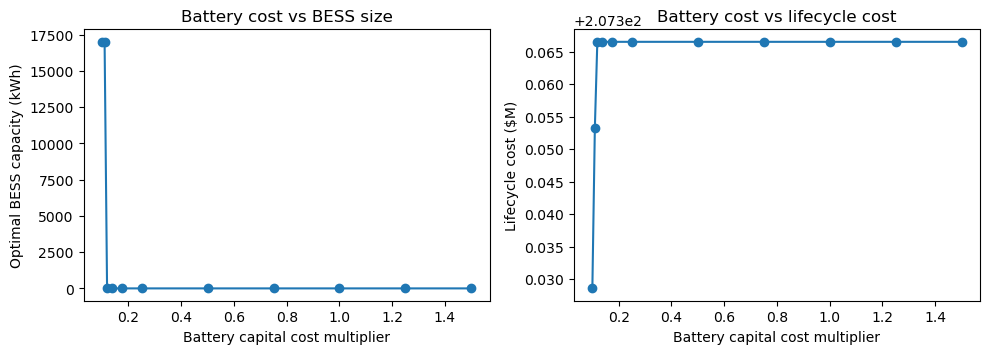

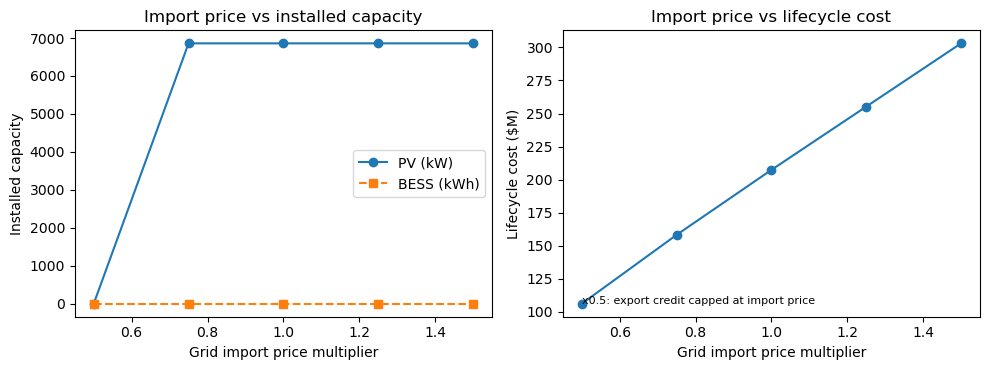

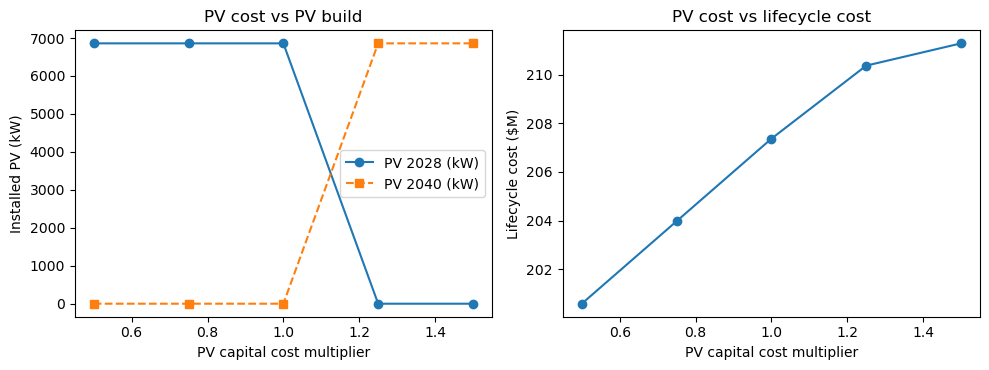

In [15]:
def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT / f"{name}.png", dpi=200); plt.show()

b = sens_B_all[sens_B_all.status == "OPTIMAL"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(b.multiplier, b["Battery total (kWh)"], "o-")
ax[0].set(xlabel="Battery capital cost multiplier", ylabel="Optimal BESS capacity (kWh)", title="Battery cost vs BESS size")
ax[1].plot(b.multiplier, b["Z ($M)"], "o-")
ax[1].set(xlabel="Battery capital cost multiplier", ylabel="Lifecycle cost ($M)", title="Battery cost vs lifecycle cost")
save(fig, "sens_battery_cost")

g = sens_G[sens_G.status == "OPTIMAL"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(g.multiplier, g["PV total (kW)"], "o-", label="PV (kW)")
ax[0].plot(g.multiplier, g["Battery total (kWh)"], "s--", label="BESS (kWh)")
ax[0].set(xlabel="Grid import price multiplier", ylabel="Installed capacity", title="Import price vs installed capacity")
ax[0].legend()
ax[1].plot(g.multiplier, g["Z ($M)"], "o-")
ax[1].set(xlabel="Grid import price multiplier", ylabel="Lifecycle cost ($M)", title="Import price vs lifecycle cost")
ax[1].annotate("x0.5: export credit capped at import price", (0.5, g["Z ($M)"].min()), fontsize=8)
save(fig, "sens_import_price")

q = sens_PV[sens_PV.status == "OPTIMAL"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(q.multiplier, q["PV 2028 (kW)"], "o-", label="PV 2028 (kW)")
ax[0].plot(q.multiplier, q["PV 2040 (kW)"], "s--", label="PV 2040 (kW)")
ax[0].set(xlabel="PV capital cost multiplier", ylabel="Installed PV (kW)", title="PV cost vs PV build")
ax[0].legend()
ax[1].plot(q.multiplier, q["Z ($M)"], "o-")
ax[1].set(xlabel="PV capital cost multiplier", ylabel="Lifecycle cost ($M)", title="PV cost vs lifecycle cost")
save(fig, "sens_pv_cost")

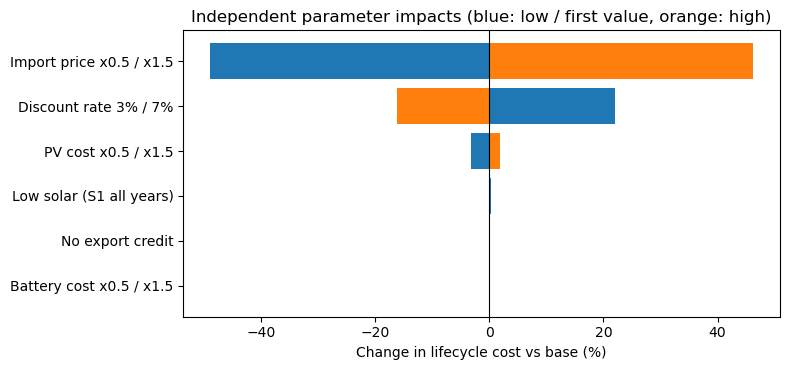

In [16]:
# Tornado: one-parameter-at-a-time change in lifecycle cost vs base (runs that needed recovery are left out)
pct = allrows["Z change vs base (%)"]
bars = [("Battery cost x0.5 / x1.5", pct.get("Battery cost x0.5"), pct.get("Battery cost x1.5")),
        ("Import price x0.5 / x1.5", pct.get("Import price x0.5"), pct.get("Import price x1.5")),
        ("PV cost x0.5 / x1.5", pct.get("PV cost x0.5"), pct.get("PV cost x1.5")),
        ("Discount rate 3% / 7%", pct.get("S3 Discount 3%"), pct.get("S3 Discount 7%")),
        ("Low solar (S1 all years)", pct.get("S1 Low solar"), None),
        ("No export credit", pct.get("S4 No export credit"), None)]
if allrows.loc["S2 Growth 4%", "status"] == "OPTIMAL":
    bars.append(("Demand growth 4%", pct.get("S2 Growth 4%"), None))
bars = sorted(bars, key=lambda b: -max(abs(x) for x in b[1:] if x is not None and not np.isnan(x)))
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (lab, a, c) in enumerate(bars[::-1]):
    for x, col in ((a, "tab:blue"), (c, "tab:orange")):
        if x is not None and not np.isnan(x):
            ax.barh(i, x, color=col)
ax.set_yticks(range(len(bars)), [b[0] for b in bars[::-1]])
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Change in lifecycle cost vs base (%)", title="Independent parameter impacts (blue: low / first value, orange: high)")
save(fig, "tornado_lifecycle_cost")

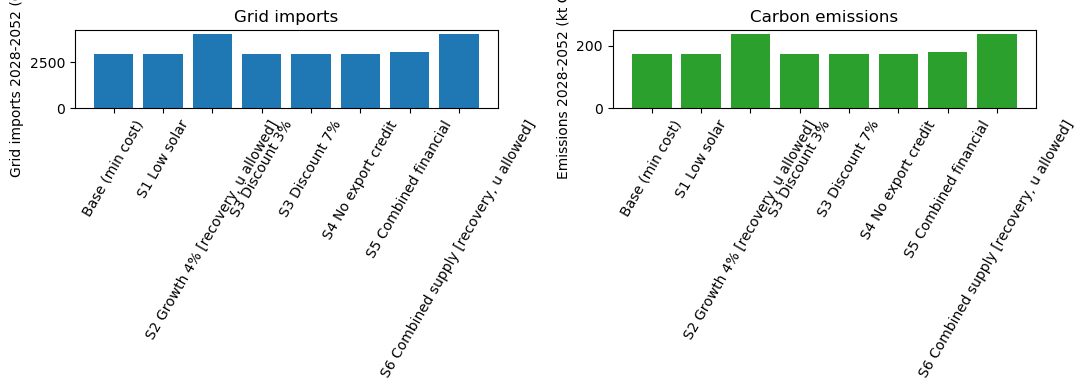

In [17]:
# Stress cases: 25-year imports and emissions (recovery runs shown where the plain run was infeasible)
s = allrows.loc[["Base (min cost)"] + [c for c in stress.index if allrows.loc[c, "status"] == "OPTIMAL"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(s.index, s["Imports (GWh)"]); ax[0].set(ylabel="Grid imports 2028-2052 (GWh)", title="Grid imports")
ax[1].bar(s.index, s["Emissions (t CO2e)"] / 1e3, color="tab:green")
ax[1].set(ylabel="Emissions 2028-2052 (kt CO2e)", title="Carbon emissions")
for a in ax:
    a.tick_params(axis="x", rotation=60)
save(fig, "stress_imports_emissions")

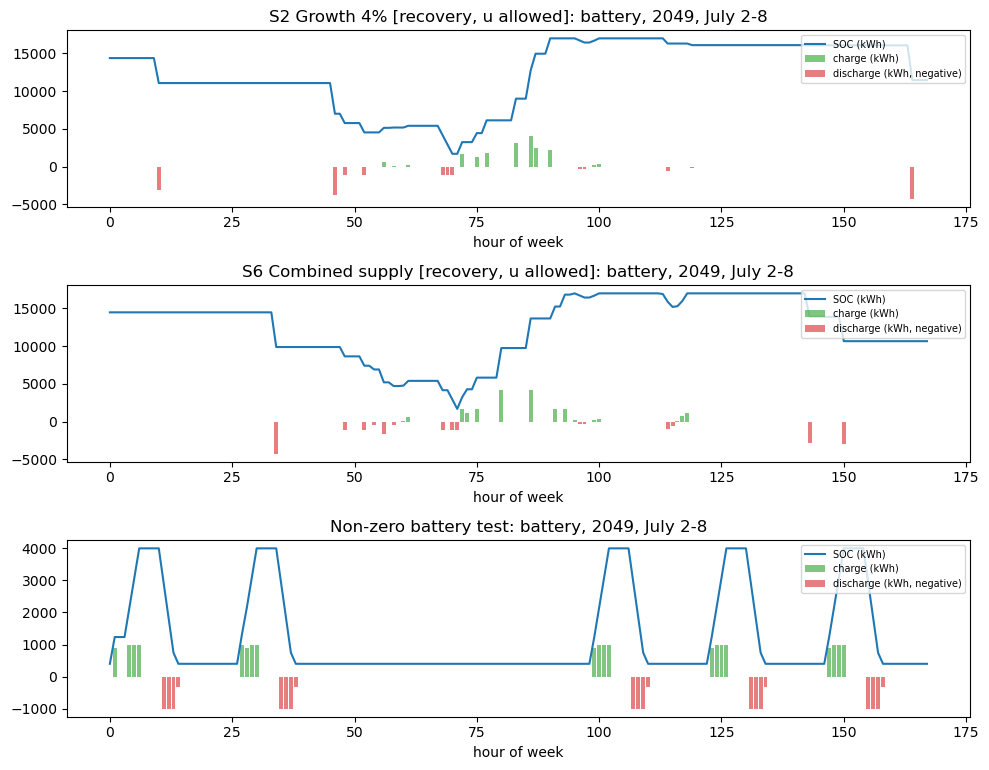

In [18]:
# Battery operation, representative week (7 days from the peak day, July 2) in 2049, for runs that install a battery
k0 = peak_day(load_inputs(Params()))
wk = slice(24 * (k0 - 1), 24 * (k0 + 6))
with_b = [c for c in allrows.index if allrows.loc[c, "Battery total (kWh)"] > TOL and details.get(c)]
main = [c for c in with_b if c in sens_B.case.values or c in sens_G.case.values or c in sens_PV.case.values
        or c in stress.index]
show = main or with_b[:1]                 # if only bisection runs build a battery, show the cheapest one that does
show = (show + ["Non-zero battery test"])[:4]
details["Non-zero battery test"] = bt_d
fig, axes = plt.subplots(len(show), 1, figsize=(10, 2.6 * len(show)), squeeze=False)
for ax, c in zip(axes[:, 0], show):
    w = details[c]["week"].iloc[wk].reset_index(drop=True)
    ax.plot(w.soc, label="SOC (kWh)")
    ax.bar(w.index, w.ch, color="tab:green", alpha=0.6, label="charge (kWh)")
    ax.bar(w.index, -w.dis, color="tab:red", alpha=0.6, label="discharge (kWh, negative)")
    ax.set(title=f"{c}: battery, 2049, July 2-8", xlabel="hour of week")
    ax.legend(fontsize=7, loc="upper right")
save(fig, "battery_week")

## Summary
Largest influence on each outcome (printed from the results table; interpretation in `analysis/findings.md`).

In [19]:
solved = allrows[allrows.status == "OPTIMAL"].drop(index="Base (min cost)")
for col in ["Z ($M)", "PV total (kW)", "Battery total (kWh)", "Imports (GWh)", "Emissions (t CO2e)"]:
    d = (solved[col] - allrows.loc["Base (min cost)", col]).abs().sort_values(ascending=False)
    print(f"{col:22s} largest change: {d.index[0]} ({solved.loc[d.index[0], col]:,.2f} vs base "
          f"{allrows.loc['Base (min cost)', col]:,.2f})")
print("Infeasible without unmet demand:", list(allrows.index[allrows.status != "OPTIMAL"]))
print("Runs that install a battery:", list(allrows.index[allrows["Battery total (kWh)"] > TOL]))

Z ($M)                 largest change: S6 Combined supply [recovery, u allowed] (393.80 vs base 207.37)
PV total (kW)          largest change: Import price x0.5 (0.00 vs base 6,860.00)
Battery total (kWh)    largest change: Battery cost x0.1 (17,000.00 vs base 0.00)
Imports (GWh)          largest change: S6 Combined supply [recovery, u allowed] (4,035.65 vs base 2,947.29)
Emissions (t CO2e)     largest change: S6 Combined supply [recovery, u allowed] (238,103.19 vs base 173,890.09)
Infeasible without unmet demand: ['S2 Growth 4%', 'S6 Combined supply']
Runs that install a battery: ['Battery cost x0.1', 'Battery cost x0.1094', 'S2 Growth 4% [recovery, u allowed]', 'S6 Combined supply [recovery, u allowed]']
